# Modelo de **Hodgkin & Huxley**

Referencias:

1. https://en.wikipedia.org/wiki/Hodgkin%E2%80%93Huxley_model
2. Eugene M. Izhikevich, Dynamical Systems in Neuroscience: The Geometry of Excitability and Bursting, Computational Neuroscience, The MIT Press (2006)
3. https://colab.research.google.com/github/kmkarakaya/ML_tutorials/blob/master/How_to_upload_an_image_to_Colab_.ipynb#scrollTo=KKTpNAGCWLeB

## **Ejercicio 1)** Importando librerías

**a)** Importe las librerías `numpy` para operar con arrays, `scipy` para utilizar rutinas de algebra lineal y `matplotlib.pyplot` para graficar.

**b)** Suba el archivo "libreria" `ode.py` que fabricó en el práctico 4), e impórtelo.

In [1]:
# 1.a)
import numpy as np
import scipy as sp
import scipy.linalg as linalg
import matplotlib.pyplot as plt

In [2]:
# 1.b)
# https://stackoverflow.com/questions/48905127/importing-py-files-in-google-colab
#import ode

def euler(f,x,t,h,p):
    """
    Calcula un paso de integración del método de Euler.

    Argumentos de entrada:

        f : R^n,R -> R^n
        x = x(t) : R^n
        t = tiempo : R
        h = paso de tiempo : R
        p = parametros : R^q

    Retorna aproximacion numérica de

        x(t+h) : R^n

    según el método de Euler.

    # Ejemplos:
    """
    return x+h*f(x,t,p)

def rk4(f,x,t,h,p):
    """
    Calcula un paso de integración del método de Runge Kutta orden 4.

    Argumentos de entrada:

        f : R^n -> R^n
        x = x(t) : R^n
        t = tiempo : R
        h = paso de tiempo : R
        p = parametros : R^q

    Retorna aproximacion numérica de

        x(t+h) : R^n

    según el método de Runge-Kutta de orden 4.

    # Ejemplos:
    """
    k1 = f(x,t,p)
    k2 = f(x+0.5*h*k1,t+0.5*h,p)
    k3 = f(x+0.5*h*k2,t+0.5*h,p)
    k4 = f(x+h*k3,t+h,p)
    return x+h*(k1+2.0*k2+2.0*k3+k4)/6.0

def integrador_ode(m,f,xa,a,b,k,p,c=lambda x,t,p:x):
    """
    Integra numéricamente la ODE

        dx/dt = f(x,t)

    sobre el intervalo t:[a,b] usando k pasos de integración y el método m, bajo condicion inicial x(a)=x0.
    No es necesario que a<b.

    Argumentos de entrada:

        m = metodo de integracion (ej. euler, rk2, etc.)
        f : R^n -> R^n
        xa = condicion inicial : R
        a = tiempo inicial : R
        b = tiempo final : R
        k = num. pasos de integracion : N
        p = parametros : R^q
        c = función condicionante : R^n,R,p -> R^n

    Retorna:

        t : R^{k+1} , t_j = a+j*h para j=0,1,...,k
        w : R^{n,k+1} , w_ij = x_i(t_j) para i=0,1,...,n-1 y j=0,1,...,k

    donde a+k*dt = b.
    """
    assert k>0
    n = len(xa)
    h = (b-a)/k
    w = np.zeros((n,k+1)) # Produce un array con forma y tipo especificada con los parametros,
                          # lleno de ceros. la forma puede ser espcificada con un entero o tupla (n,k+1)
    t = np.zeros(k+1)
    w[:,0] = xa           # actualiza la posicion inicial (columna de indice 0) de las variables con los valores
                          # de las condiciones iniciales
    t[0] = a              # actualiza la posicion cero con el valor del tiempo inicial

    for j in range(k):    #Aca se produce la iteración en j

        t[j+1] = t[j] + h                # iteracion tiempo
        w[:,j+1] = m(f,w[:,j],t[j],h,p)  # iteracion de w
        w[:,j+1] = c(w[:,j+1],t[j+1],p)  # condicion sobre w

    return t,w

## **Ejercicio 2)** Modelo de Hodgkin y Huxley

## Teoría

### Las neuronas son capacitores

Según el modelo de Hodgkin y Huxley, a primera vista las neuronas funcionan como capacitores evidenciando una diferencia de potencial eléctrico entre el exterior y el interior debido a las diferentes concentraciones de cargas iónicas que pueden existir entre estas dos regiones.
En el esquema, se utilizan agujas muy finas para inyectar una corriente iónica $i$ al interior de una neurona sumergida en una solución salina conductora.

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/esquema1.png?raw=true:, width=100" alt="My Image" width=300>

Recordemos que un capacitor sujeto a una diferencia de potencial $v:=v_A-v_B$ adquiere una carga $q=cv$.
La carga crece según $\dot{q}=i$, donde $i$ denota la corriente de carga eléctrica que va desde el exterior hacia el interior.

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/circuito1.png?raw=true:, width=100" alt="My Image" width=500>

### Las neuronas son capacitores con fugas

Si miramos un poco más en detalle, veremos que la membrana de las neuronas tienen canales por donde pueden circular iones.
Podemos pensar a los canales como agujeritos en la membrana por donde la carga se fuga, que podemos modelar como a una resistencia conectada en paralelo al capacitor.

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/circuito2.png?raw=true:, width=100" alt="My Image" width=500>

La corriente $i_g=g(v_A-v_B)=gv$, donde $i_g$ denota una corriente que va desde el interior hacia el exterior.

### Las neuronas tienen generadores de tensión

Los canales pueden ser selectivos.
Por ejemplo, algunos canales sólo dejan pasar los iones $\mathrm{K}^+$.
Por ende, si inyectamos al interior de la neurona una mezcla de iones $\mathrm{K}^+$ y $\mathrm{Cl}^-$, de manera que la carga total se encuentre equilibrada, los iones $\mathrm{K}^+$ comenzarán a difundir desde el interior hacia el exterior a travéz de los canales selectivos, mientras que los de $\mathrm{Cl}^-$ se quedarán en el interior, provocando un excedente de cargas negativas en el interior que crecen en el tiempo hasta que la diferencia de potencial emergente frena la corriente de iónes $\mathrm{K}^+$.

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/baterias.png?raw=true:, width=100" alt="My Image" width=500>

A este fenómeno se lo denomina potencial de Nernst o de reversión y se lo incorpora al circuito que modela la neurona como una batería conectada en serie a la resistencia asociada a cada canal

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/circuito3.png?raw=true:, width=100" alt="My Image" width=500>

Ahora, la corriente es $i_g=g(v_A-v_C)=g(v_A-(v_B+e_g))=g(v_A-v_B-e_g)=g(v-e_g)=:g(v-v_g)$, donde en la última iguadad reconocemos la definición del potencial de Nernst $v_g$.

Si la batería se encuentra en sentido inverso

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/circuito4.png?raw=true:, width=100" alt="My Image" width=500>

entonces $i_g=g(v_A-v_C)=g(v_A-(v_B-e_g))=g(v_A-v_B+e_g)=g(v+e_g)=:g(v-v_g)$, por lo que el potencial de Nernst resulta negativo, $v_g=-e_g$.

### Algunos canales forman reóstatos (resistencias de conductancia variable)

Algunos canales tienen varias compuertas que se abren o cierran, permitiendo o impidiendo el paso de iones. Un mismo canal puede tener varias compuertas, y para que el canal sea conductor deben encontrarse abiertas las compuertas correspondientes.

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/compuertas.png?raw=true:, width=100" alt="My Image" width=500>

La conductividad asociada a estos canales, depende de la fracción de compuertas abiertas en cada tipo de canal.
Según el modelo, la conductancia total asociada a los canales de $\mathrm{Na}$ se aproxima por

$$g_{\mathrm{Na}} = \bar{g}_{\mathrm{Na}}p_{\mathrm{Na}}$$

donde $\bar{g}_{\mathrm{Na}}$ es la conductancia de $\mathrm{Na}$ máxima posible y

$$p_{\mathrm{Na}} = m^3h$$

es la fracción de canales de $\mathrm{Na}$ que se encuentran en estado conductor.
Aquí $m$ y $h$ son las fracciones de compuertas de activación e inactivación, respectivamente, que se encuentran abiertas.
Los canales de $\mathrm{Na}$ poseen 3 compuertas de activación y 1 de inactivación, por lo que, asumiendo que se abren de manera independiente, $m$ tiene un exponente 3 y $h$ un exponente 1.

De manera similar, la conductancia asociada a los canales de $\mathrm{K}$ se aproxima por

$$g_{\mathrm{K}} = \bar{g}_{\mathrm{K}}p_{\mathrm{K}}$$

donde $\bar{g}_{\mathrm{K}}$ es la conductancia de $\mathrm{K}$ máxima posible,

$$p_{\mathrm{K}} = n^4$$

es la fracción de canales de $\mathrm{K}$ abiertos y $n$ es la fracción de compuertas abiertas en este tipo de canales.
Cada canal de $\mathrm{K}$ posee 4 compuertas de tipo $n$, de ahí el exponente 4.

Estas aproximaciones asumen que las compuertas abren o cierran de manera independiente, dependiendo de la diferencia de potencial de membrana existente $v$.
Más precisamente, las fracciones de compuertas abiertas de cada tipo satisfacen

\begin{eqnarray}
\dot{n}(t)&=&\alpha_n(v(t))(1-n(t))-\beta_n(v(t)) n(t)\\
\dot{m}(t)&=&\alpha_m(v(t))(1-m(t))-\beta_m(v(t)) m(t)\\
\dot{h}(t)&=&\alpha_h(v(t))(1-h(t))-\beta_h(v(t)) h(t)
\end{eqnarray}

donde

\begin{eqnarray}
\alpha_h(v)&=&\frac{0.07}{ms}\,\exp\bigg(-\frac{v}{20\,mV}\bigg)\\
\alpha_m(v)&=&\frac{0.1}{ms\,mV}\frac{25\,mV-v}{\exp\big(\frac{25\,mV-v}{10\,mV}\big)-1}\\
\alpha_n(v)&=&\frac{0.01}{ms\,mV}\frac{10\,mV-v}{\exp\big(\frac{10\,mV-v}{10\,mV}\big)-1}\\
\end{eqnarray}

representan las tasas a las cuales las compuertas cerradas de cada tipo abren y

\begin{eqnarray}
\beta_h(v)&=&\frac{1}{ms}\frac{1}{\exp\big(\frac{30\,mV-v}{10\,mV}\big)+1}\\
\beta_m(v)&=&\frac{4}{ms}\exp\bigg(-\frac{v}{18\,mV}\bigg)\\
\beta_n(v)&=&\frac{0.125}{ms}\exp\bigg(-\frac{v}{80\,mV}\bigg)
\end{eqnarray}

representan las tasas a las cuales las compuertas abiertas de cada tipo cierran, respectivamente.

En resumen, al modelo de neurona de Hodgkin y Huxley se lo puede representar por el circuito

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/circuito5.png?raw=true:, width=100" alt="My Image" width=500>

en donde reconocemos la existencia de 3 canales iónicos: uno de pérdida (leak) de conductancia constante $g_l$, potencial de Nernst $v_l=e_l$ y por el que fluye una corriente $i_l$, uno de $\mathrm{Na}$ de conductancia variable $g_{\mathrm{Na}}$, potencial de Nernst $v_{\mathrm{Na}}=e_{\mathrm{Na}}$ y por el que fluye una corriente $i_{\mathrm{Na}}$, y uno de $\mathrm{K}$ de conductancia $g_{\mathrm{K}}$, potencial de Nernst $v_{\mathrm{K}}=-e_{\mathrm{K}}$ y por el que fluye una corriente $i_{\mathrm{K}}$.

Aplicando la ley de Kirchoff para corrientes, vemos que

$$i=i_{\mathrm{Na}}+i_{\mathrm{K}}+i_l+i_c$$

Es decir, la corriente $i$ inyectada al interior de la neurona se divide en dos partes.
Por un lado, en la corriente $i_m=i_{\mathrm{Na}}+i_{\mathrm{K}}+i_l$ que fluye a travéz de los canales en la membrana,
y por otro lado, en la corriente $i_c$ que carga el capacitor.

Remplazando, obtenemos una ODE para el potencial de membrana

\begin{eqnarray}
i_c&=&i-i_{\mathrm{Na}}+i_{\mathrm{K}}+i_l\\
c\dot{v}&=&i-g_{\mathrm{Na}}(v-v_{\mathrm{Na}})-g_{\mathrm{K}}(v-v_{\mathrm{K}})-g_{l}(v-v_{l})\\
\dot{v}&=&c^{-1}(i-\bar{g}_{\mathrm{Na}}m^3h(v-v_{\mathrm{Na}})-\bar{g}_{\mathrm{K}}n^4(v-v_{\mathrm{K}})-g_{l}(v-v_{l}))
\end{eqnarray}

La última línea de la anterior ecuación, junto con las ODEs anteriormente mencionadas para $n$, $m$ y $h$, determinan el sistema de ODEs del modelo de Hodgkin y Huxley.

### Comportamiento cualitativo

Durante el proceso de disparo, diferentes compuertas se abren y cierran a diferentes tiempos.
El siguiente esquema resume el proceso en 4 etapas

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/channels.png?raw=true:, width=100" alt="My Image" width=300>

Estimaciones de los tiempos carácterísticos (de apertura/cierre) y los valores de equilibrio de las fracciones de compuertas abiertas de cada tipo que observan en las diferentes etapas, se pueden obtener de reescribir las ODEs para $n$, $m$ y $h$ de la forma

\begin{eqnarray}
\dot{n}(t)&=&\tau_n^{-1}(v(t))(n_{\infty}(v(t))-n(t))\\
\dot{m}(t)&=&\tau_m^{-1}(v(t))(m_{\infty}(v(t))-m(t))\\
\dot{h}(t)&=&\tau_h^{-1}(v(t))(h_{\infty}(v(t))-h(t))
\end{eqnarray}

donde

\begin{eqnarray}
\tau_n(v)&=&(\alpha_n(v)+\beta_n(v))^{-1}\\
\tau_m(v)&=&(\alpha_m(v)+\beta_m(v))^{-1}\\
\tau_h(v)&=&(\alpha_h(v)+\beta_h(v))^{-1}
\end{eqnarray}

y

\begin{eqnarray}
n_{\infty}(v)&=&\tau_n(v)\alpha_n(v)\\
m_{\infty}(v)&=&\tau_m(v)\alpha_m(v)\\
h_{\infty}(v)&=&\tau_h(v)\alpha_h(v)
\end{eqnarray}

Finalmente, listamos los valores de los parámetros del modelo (ver libro de Izhikevich)

* $c=1\,\mu F/cm^2$ : capacitancia de membrana
* $\bar{g}_{\mathrm{Na}}=120\,mS/cm^2$ : conductancia máxima de $\mathrm{Na}$
* $\bar{g}_{\mathrm{K}}=36\,mS/cm^2$ : conductancia máxima de $\mathrm{K}$
* $g_l=0.3\,mS/cm^2$ : conductancia máxima de perdida
* $v_{\mathrm{Na}}=120\,mV$ : potencial de reversión de la corriente de $\mathrm{Na}$
* $v_{\mathrm{K}}=-12\,mV$ : potencial de reversión de la corriente de $\mathrm{K}$
* $v_l=10.6\,mV$ : potencial de reversión de la corriente de perdida
* $i(t)\sim 10\,\mu A/cm^2$ : corriente de entrada al tiempo $t$
* $t \sim 5\,ms$ : tiempo

Aclaración, los valores de los potenciales de Nernst se toman en referencia al potencial de equilibrio definido en $v\approx 0\, mV$.

## Ejercicio 2) implementación

**1)** Usando la sección de teoría y las referencias, implemente el modelo de Hodgkin y Huxley el integrador numérico de ODEs tipo Runge-Kutta de orden 4 del práctico 4.

**2)** Grafique los valores de equilibrio de las distintas fracciones $n_{\infty}$, $m_{\infty}$ y $h_{\infty}$ de compuertas abiertas, en función de la diferencia de potencial de membrana $v$.

**3)** Grafique los tiempos característicos $\tau_m$, $\tau_n$ y $\tau_h$ de apertura y cierre, asociados a los distintos tipos de compuertas, en función de la diferencia de potencial de membrana $v$.

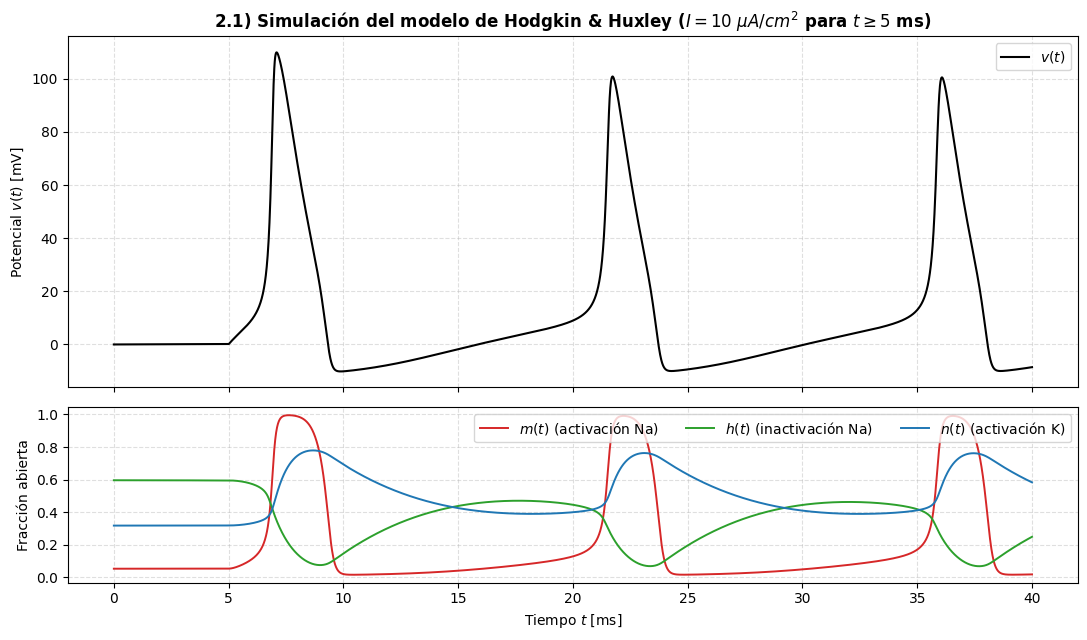

In [11]:
# 2.1

#Funciones de transición de compuertas (alpha y beta)
def alpha_n(v):
    x = (10.0 - v) / 10.0
    return 0.01 * 10.0 * np.where(np.abs(x) < 1e-6, 1.0 - 0.5 * x, x / (np.exp(x) - 1.0))

def beta_n(v):
    return 0.125 * np.exp(-v / 80.0)

def alpha_m(v):
    x = (25.0 - v) / 10.0
    return 0.1 * 10.0 * np.where(np.abs(x) < 1e-6, 1.0 - 0.5 * x, x / (np.exp(x) - 1.0))

def beta_m(v):
    return 4.0 * np.exp(-v / 18.0)

def alpha_h(v):
    return 0.07 * np.exp(-v / 20.0)

def beta_h(v):
    return 1.0 / (np.exp((30.0 - v) / 10.0) + 1.0)

#  Tiempos característicos y valores estacionarios
def tau_y_inf(v):
    an, bn = alpha_n(v), beta_n(v)
    am, bm = alpha_m(v), beta_m(v)
    ah, bh = alpha_h(v), beta_h(v)

    tau_n, n_inf = 1.0 / (an + bn), an / (an + bn)
    tau_m, m_inf = 1.0 / (am + bm), am / (am + bm)
    tau_h, h_inf = 1.0 / (ah + bh), ah / (ah + bh)
    return (tau_n, n_inf), (tau_m, m_inf), (tau_h, h_inf)

#  Sistema de ODEs de Hodgkin-Huxley
def hodgkin_huxley_ode(estado, t, p):
    v, n, m, h = estado
    c, g_Na, g_K, g_l, v_Na, v_K, v_l, I_func = p

    i_Na = g_Na * (m**3) * h * (v - v_Na)
    i_K  = g_K  * (n**4) * (v - v_K)
    i_l  = g_l  * (v - v_l)

    dv = (I_func(t) - i_Na - i_K - i_l) / c
    dn = alpha_n(v) * (1.0 - n) - beta_n(v) * n
    dm = alpha_m(v) * (1.0 - m) - beta_m(v) * m
    dh = alpha_h(v) * (1.0 - h) - beta_h(v) * h

    return np.array([dv, dn, dm, dh])

#  Parámetros estándar e integración con RK4
c = 1.0
g_Na, g_K, g_l = 120.0, 36.0, 0.3
v_Na, v_K, v_l = 120.0, -12.0, 10.6

# Corriente de entrada: pulso de 10 uA/cm^2 a partir de t = 5 ms
I_ext = lambda t: 10.0 if t >= 5.0 else 0.0

p_hh = (c, g_Na, g_K, g_l, v_Na, v_K, v_l, I_ext)

# Condiciones iniciales en equilibrio (v0 = 0 mV)
v0 = 0.0
(_, n0), (_, m0), (_, h0) = tau_y_inf(v0)
xa = np.array([v0, n0, m0, h0])

# Integración en t ∈ [0, 40] ms con paso h = 0.01 ms
a, b_t = 0.0, 40.0
paso = 0.01
k = int((b_t - a) / paso)

t, w = integrador_ode(rk4, hodgkin_huxley_ode, xa, a, b_t, k, p_hh)
v, n, m, h = w[0], w[1], w[2], w[3]

# Gráfico de verificación del tren de potenciales de acción y evolución de compuertas
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

ax1.plot(t, v, color='black', lw=1.5, label='$v(t)$')
ax1.set_ylabel('Potencial $v(t)$ [mV]')
ax1.set_title('2.1) Simulación del modelo de Hodgkin & Huxley ($I = 10\\ \\mu A/cm^2$ para $t \\geq 5$ ms)', fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='upper right')

ax2.plot(t, m, label='$m(t)$ (activación Na)', color='#d62728', lw=1.4)
ax2.plot(t, h, label='$h(t)$ (inactivación Na)', color='#2ca02c', lw=1.4)
ax2.plot(t, n, label='$n(t)$ (activación K)', color='#1f77b4', lw=1.4)
ax2.set_ylabel('Fracción abierta')
ax2.set_xlabel('Tiempo $t$ [ms]')
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='upper right', ncol=3)

plt.tight_layout()
plt.show()

Este gráfico muestra cómo responde una neurona cuando le inyectamos una corriente eléctrica constante a partir de los $5\text{ ms}$. Está dividido en dos partes que ocurren exactamente al mismo tiempo: arriba el voltaje de la neurona $v(t)$ y abajo el movimiento de sus compuertas ($m, h, n$).

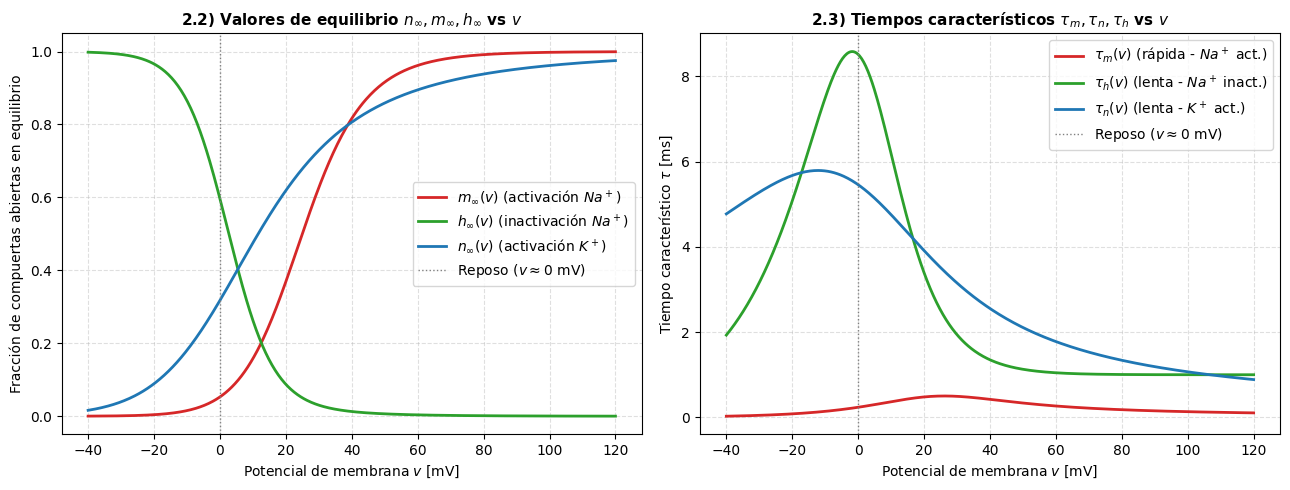

In [12]:
# Rango de diferencia de potencial de membrana v [mV]
v_grid = np.linspace(-40.0, 120.0, 500)
(tau_n, n_inf), (tau_m, m_inf), (tau_h, h_inf) = tau_y_inf(v_grid)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# 2.2) Valores de equilibrio n_inf, m_inf, h_inf vs v
ax1.plot(v_grid, m_inf, label=r'$m_\infty(v)$ (activación $Na^+$)', color='#d62728', lw=2)
ax1.plot(v_grid, h_inf, label=r'$h_\infty(v)$ (inactivación $Na^+$)', color='#2ca02c', lw=2)
ax1.plot(v_grid, n_inf, label=r'$n_\infty(v)$ (activación $K^+$)', color='#1f77b4', lw=2)

ax1.axvline(0.0, color='gray', linestyle=':', lw=1, label='Reposo ($v \\approx 0$ mV)')
ax1.set_title('2.2) Valores de equilibrio $n_\\infty, m_\\infty, h_\\infty$ vs $v$', fontsize=11, fontweight='bold')
ax1.set_xlabel('Potencial de membrana $v$ [mV]')
ax1.set_ylabel('Fracción de compuertas abiertas en equilibrio')
ax1.set_ylim(-0.05, 1.05)
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='center right')

# 2.3) Tiempos característicos tau_m, tau_n, tau_h vs v
ax2.plot(v_grid, tau_m, label=r'$\tau_m(v)$ (rápida - $Na^+$ act.)', color='#d62728', lw=2)
ax2.plot(v_grid, tau_h, label=r'$\tau_h(v)$ (lenta - $Na^+$ inact.)', color='#2ca02c', lw=2)
ax2.plot(v_grid, tau_n, label=r'$\tau_n(v)$ (lenta - $K^+$ act.)', color='#1f77b4', lw=2)

ax2.axvline(0.0, color='gray', linestyle=':', lw=1, label='Reposo ($v \\approx 0$ mV)')
ax2.set_title('2.3) Tiempos característicos $\\tau_m, \\tau_n, \\tau_h$ vs $v$', fontsize=11, fontweight='bold')
ax2.set_xlabel('Potencial de membrana $v$ [mV]')
ax2.set_ylabel('Tiempo característico $\\tau$ [ms]')
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

Análisis de las curvas de equilibrio y tiempos característicos

Estos dos gráficos muestran cómo se comportan las compuertas de la neurona en función del potencial de membrana $v$:

* **Valores de equilibrio $m_\infty(v), h_\infty(v), n_\infty(v)$ (panel izquierdo):** Indican qué fracción de cada tipo de compuerta tiende a abrirse a un voltaje dado. Cuando la membrana se despolariza (sube $v$), las compuertas de activación de sodio ($m_\infty$) y de potasio ($n_\infty$) tienden a abrirse ($m_\infty, n_\infty \to 1$), mientras que la compuerta de inactivación de sodio ($h_\infty$) tiende a cerrarse ($h_\infty \to 0$).
* **Tiempos característicos $\tau_m(v), \tau_h(v), \tau_n(v)$ (panel derecho):** Indican qué tan rápido responde cada compuerta ante un cambio de voltaje. Como $\tau_m(v)$ es un orden de magnitud menor que $\tau_h(v)$ y $\tau_n(v)$ en todo el rango fisiológico, la apertura de los canales de $\text{Na}^+$ ocurre de manera casi instantánea frente a un estímulo, mientras que el cierre del $\text{Na}^+$ ($h$) y la apertura del $\text{K}^+$ ($n$) actúan como frenos retardados que llegan un par de milisegundos después para repolarizar la membrana y generar el potencial de acción.

## Ejercicio 3) valores de equilibrio

**1)** Integre el sistema de ODEs del modelo de Hodgkin y Huxley sujeto a una corriente total $i(t)=0$ para todo $t$. Use la condición inicial $v_0=0mV$, $n_0=m_0=h_0=0$ y $t_0=0ms$. Integre hasta el tiempo final $t_f=500ms$ usando un paso temporal $dt=0.01ms$.

**2)** Grafique el potencial de membrana en función del tiempo, i.e. grafique $v(t)$ vs $t$ en el rango calculado.

**3)** Grafique las diferentes corrientes de iones cruzando la membrana en función del tiempo, i.e. grafique  la corriente de iones de sodio $i_{Na}(t)$, la corriente de iones de potasio $i_K(t)$ y la corriente de pérdida $i_l(t)$ vs $t$ en el rango calculado.

**4)** Grafique las fracción de compuertas abiertas de cada tipo en función del tiempo, i.e. grafique $n(t)$, $m(t)$ y $h(t)$ vs $t$ en el rango calculado.

**5)** Almacene los valores de equilibrio a corriente nula de las variables dinámicas usando los valores de las mismas obtenidos a tiempos largos. Es decir, almacene los valores $v^* \approx v(t_f)$, $n^* \approx n(t_f)$, $m^* \approx m(t_f)$ y $h^* \approx h(t_f)$, para ser utilizado como condiciones iniciales en futuras integraciones de las ODEs del modelo de Hodgkin y Huxley.

Valores de equilibrio a corriente nula (t = 500 ms):
  v* = 0.046215 mV
  n* = 0.318385
  m* = 0.053222
  h* = 0.594504


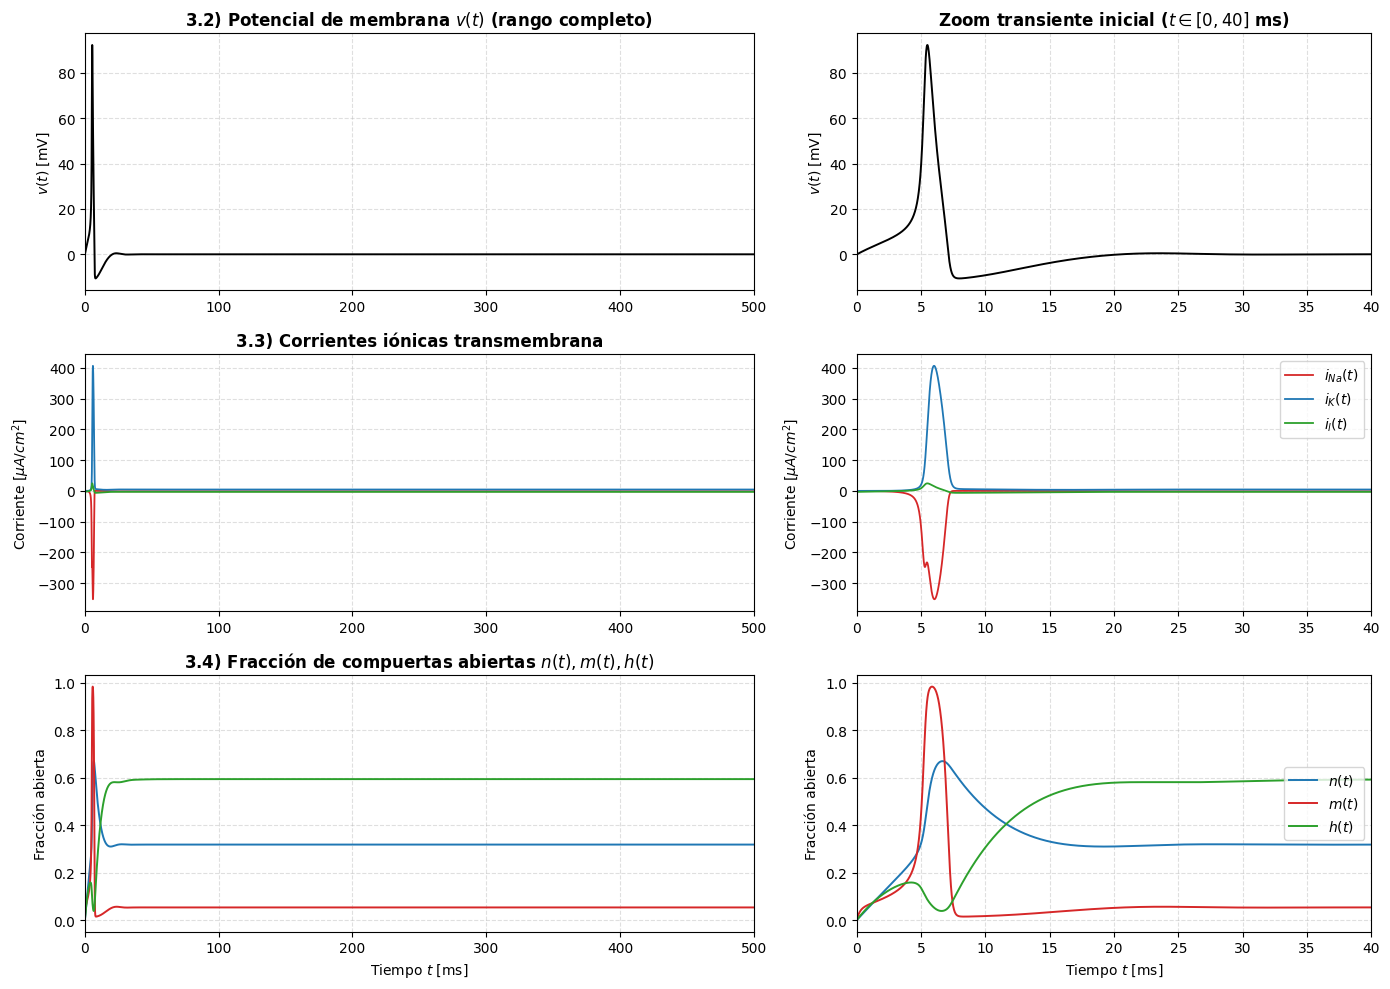

In [13]:
# 3.1) Integración con corriente nula i(t) = 0 y condiciones iniciales en cero
I_nula = lambda t: 0.0
p_eq = (c, g_Na, g_K, g_l, v_Na, v_K, v_l, I_nula)

xa_cero = np.array([0.0, 0.0, 0.0, 0.0])  # [v0, n0, m0, h0]
t0, tf = 0.0, 500.0
dt = 0.01
k = int((tf - t0) / dt)

t, w = integrador_ode(rk4, hodgkin_huxley_ode, xa_cero, t0, tf, k, p_eq)
v, n, m, h = w[0], w[1], w[2], w[3]

# Calculamos las corrientes iónicas en cada instante t
i_Na = g_Na * (m**3) * h * (v - v_Na)
i_K  = g_K  * (n**4) * (v - v_K)
i_l  = g_l  * (v - v_l)

# 3.5) Almacenamos los valores de equilibrio en t = tf (500 ms)
v_star, n_star, m_star, h_star = w[:, -1]
xa_eq = np.array([v_star, n_star, m_star, h_star])

print("Valores de equilibrio a corriente nula (t = 500 ms):")
print(f"  v* = {v_star:.6f} mV")
print(f"  n* = {n_star:.6f}")
print(f"  m* = {m_star:.6f}")
print(f"  h* = {h_star:.6f}")

# --- Gráficos de los incisos 3.2, 3.3 y 3.4 ---
# Mostramos a la izquierda el rango completo [0, 500] ms y a la derecha el transiente inicial [0, 40] ms
fig, axes = plt.subplots(3, 2, figsize=(14, 10), gridspec_kw={'width_ratios': [1.3, 1]})

# 3.2) Potencial de membrana v(t) vs t
for col, xlim in enumerate([(0, 500), (0, 40)]):
    axes[0, col].plot(t, v, color='black', lw=1.4)
    axes[0, col].set_xlim(xlim)
    axes[0, col].set_ylabel('$v(t)$ [mV]')
    axes[0, col].grid(True, linestyle='--', alpha=0.4)
axes[0, 0].set_title('3.2) Potencial de membrana $v(t)$ (rango completo)', fontweight='bold')
axes[0, 1].set_title('Zoom transiente inicial ($t \\in [0, 40]$ ms)', fontweight='bold')

# 3.3) Corrientes iónicas i_Na(t), i_K(t), i_l(t) vs t
for col, xlim in enumerate([(0, 500), (0, 40)]):
    axes[1, col].plot(t, i_Na, label='$i_{Na}(t)$', color='#d62728', lw=1.3)
    axes[1, col].plot(t, i_K,  label='$i_{K}(t)$',  color='#1f77b4', lw=1.3)
    axes[1, col].plot(t, i_l,  label='$i_{l}(t)$',   color='#2ca02c', lw=1.3)
    axes[1, col].set_xlim(xlim)
    axes[1, col].set_ylabel('Corriente [$\\mu A/cm^2$]')
    axes[1, col].grid(True, linestyle='--', alpha=0.4)
axes[1, 0].set_title('3.3) Corrientes iónicas transmembrana', fontweight='bold')
axes[1, 1].legend(loc='upper right')

# 3.4) Fracción de compuertas abiertas n(t), m(t), h(t) vs t
for col, xlim in enumerate([(0, 500), (0, 40)]):
    axes[2, col].plot(t, n, label='$n(t)$', color='#1f77b4', lw=1.4)
    axes[2, col].plot(t, m, label='$m(t)$', color='#d62728', lw=1.4)
    axes[2, col].plot(t, h, label='$h(t)$', color='#2ca02c', lw=1.4)
    axes[2, col].set_xlim(xlim)
    axes[2, col].set_ylabel('Fracción abierta')
    axes[2, col].set_xlabel('Tiempo $t$ [ms]')
    axes[2, col].grid(True, linestyle='--', alpha=0.4)
axes[2, 0].set_title('3.4) Fracción de compuertas abiertas $n(t), m(t), h(t)$', fontweight='bold')
axes[2, 1].legend(loc='center right')

plt.tight_layout()
plt.show(

### Análisis de los resultados: convergencia al equilibrio a corriente nula

Al integrar el sistema con corriente externa nula ($i(t) = 0$) partiendo desde todas las compuertas cerradas ($n_0 = m_0 = h_0 = 0$) y voltaje $v_0 = 0\text{ mV}$, se observa el siguiente comportamiento:

* **Transiente inicial y disparo espontáneo ($t \in [0, 25]\text{ ms}$):** Como la condición inicial elegida no corresponde al estado de reposo natural de la membrana, durante los primeros milisegundos las compuertas comienzan a acomodarse hacia sus valores de equilibrio. Debido a que las compuertas de sodio ($m$) responden mucho más rápido que las de potasio ($n$), se produce un único potencial de acción espontáneo alrededor de $t \approx 5.5\text{ ms}$ (alcanzando un pico de $\sim +92\text{ mV}$), acompañado por un pulso negativo (entrante) de corriente de sodio $i_{\text{Na}}(t)$ y un pulso positivo (saliente) de corriente de potasio $i_{\text{K}}(t)$ que repolariza la membrana.
* **Estabilización en el estado de reposo ($t > 25\text{ ms}$):** Una vez extinguido el transiente inicial, todas las variables dinámicas se estabilizan en líneas completamente horizontales hasta $t_f = 500\text{ ms}$, alcanzando el punto fijo estable de reposo de la neurona:
  * $v^* \approx 0.046\text{ mV}$
  * $n^* \approx 0.318$
  * $m^* \approx 0.053$
  * $h^* \approx 0.595$
* **Utilidad de almacenar $(v^*, n^*, m^*, h^*)$:** Guardar estos valores estacionarios permite iniciar las simulaciones siguientes directamente desde el equilibrio fisiológico real de la membrana, evitando que aparezca el disparo transiente artificial inicial cuando $t = 0$.

## Ejercicio 4) estímulo débil y estímulo fuerte

**1)** Implemente una función de corriente de entrada o membrana dada por:

$$
i(t) = \left\{
\begin{array}{ll}
10 \mu A/cm^2, & t\in [2ms,2.5ms] \\
30 \mu A/cm^2, & t\in [10ms,10.5ms] \\
0 \mu A/cm^2, & c.c. \\
\end{array}
\right.
$$

Aquí, $c.c.$ indica *en caso contrario*. Esta corriente representa un estímulo débil seguido de uno fuerte. Grafíque la corriente $i(t)$ vs $t$ en el rango $t\in[0ms,20ms]$.

**2)** Integre nuevamente el sistema de ODEs del modelo de Hodgkin y Huxley sujeto a la corriente del inciso anterior. Use como condición inicial a tiempo $t=0$ los valores de equilibrio estimados en el ejercicio anterior. Integre hasta el tiempo final $t_f=500ms$ usando un paso temporal $dt=0.01ms$.

**3)** Grafique el potencial de membrana en función del tiempo, i.e. $v(t)$ vs $t$ en el rango calculado.

**4)** Grafique la evolución de las fraciones de compuertas abiertas, $n(t)$, $m(t)$ y $h(t)$ vs $t$.

**5)** Discuta como responde la neurona en el primer impulso a $t=2ms$. Luego, como responde al segundo impulso a $t=10ms$. Existe una diferencia? Explique.


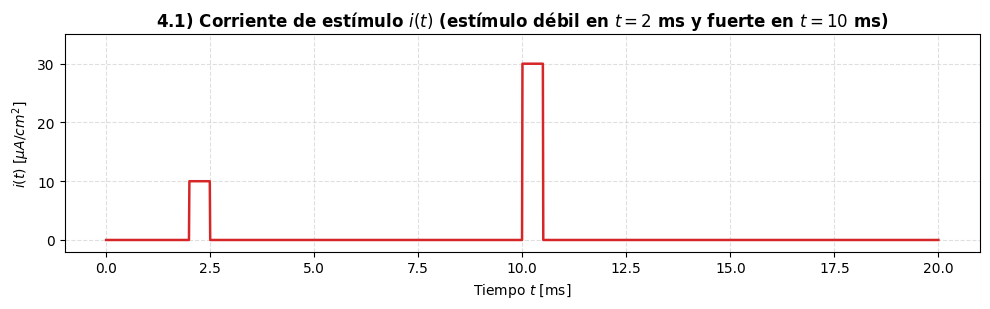

In [14]:
# 4.1) Definición de la función de corriente con dos pulsos (débil y fuerte)
def I_pulsos(t):
    if 2.0 <= t <= 2.5:
        return 10.0
    elif 10.0 <= t <= 10.5:
        return 30.0
    else:
        return 0.0

# Gráfico de i(t) vs t en el rango t ∈ [0, 20] ms
t_muestra = np.linspace(0.0, 20.0, 2000)
i_muestra = np.array([I_pulsos(ti) for ti in t_muestra])

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t_muestra, i_muestra, color='#d62728', lw=1.8)
ax.set_title('4.1) Corriente de estímulo $i(t)$ (estímulo débil en $t=2$ ms y fuerte en $t=10$ ms)', fontweight='bold')
ax.set_xlabel('Tiempo $t$ [ms]')
ax.set_ylabel('$i(t)$ [$\\mu A/cm^2$]')
ax.set_ylim(-2, 35)
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Análisis del estímulo de entrada $i(t)$ (Inciso 4.1)

En el gráfico se observa la corriente externa aplicada a la membrana en el intervalo $t \in [0, 20]\text{ ms}$, compuesta por dos pulsos breves de $0.5\text{ ms}$ de duración cada uno:
* **Estímulo débil ($t \in [2, 2.5]\text{ ms}$):** Un pulso rectangular de amplitud $i = 10\ \mu\text{A/cm}^2$.
* **Estímulo fuerte ($t \in [10, 10.5]\text{ ms}$):** Un segundo pulso rectangular con el triple de intensidad ($i = 30\ \mu\text{A/cm}^2$), aplicado luego de dejar que la membrana regrese al reposo.

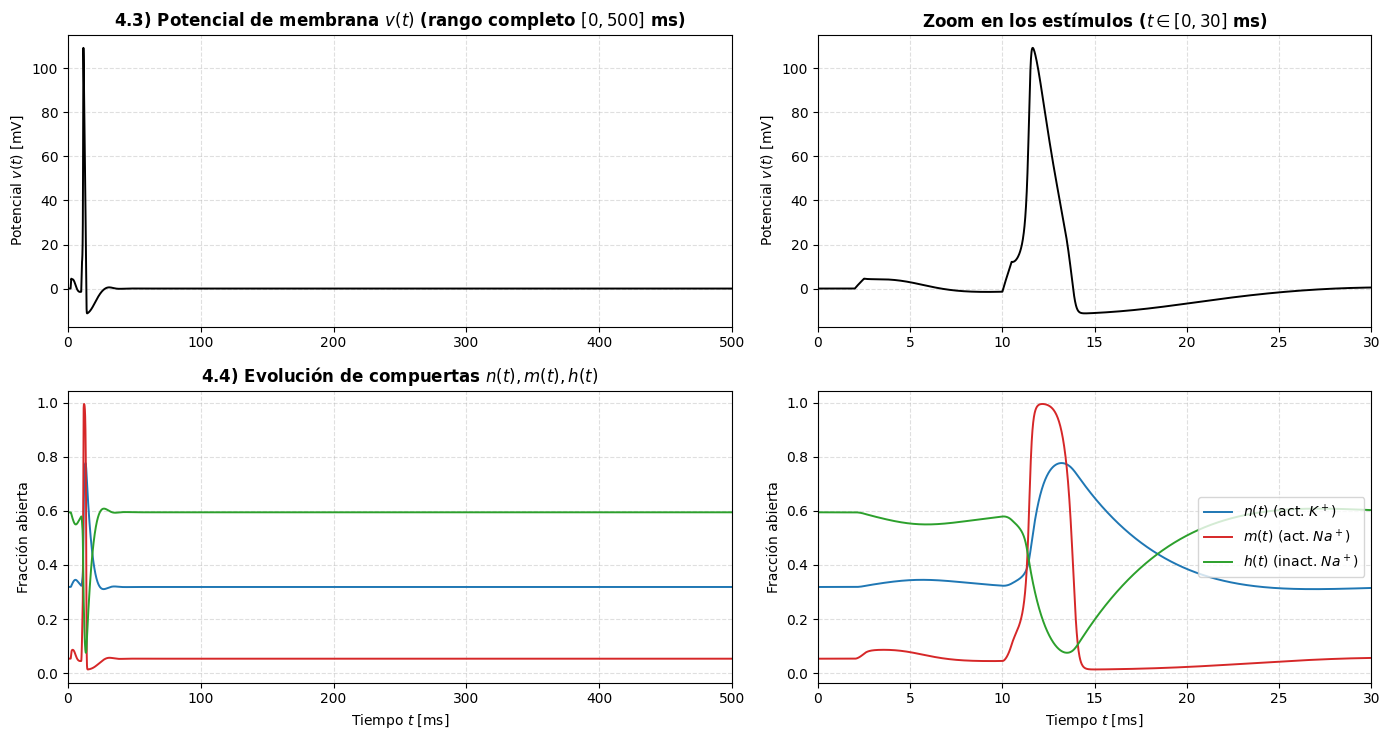

In [15]:
# 4.2) Integración del modelo de Hodgkin-Huxley partiendo del equilibrio xa_eq
p_pulsos = (c, g_Na, g_K, g_l, v_Na, v_K, v_l, I_pulsos)

t0, tf = 0.0, 500.0
dt = 0.01
k = int((tf - t0) / dt)

t, w = integrador_ode(rk4, hodgkin_huxley_ode, xa_eq, t0, tf, k, p_pulsos)
v, n, m, h = w[0], w[1], w[2], w[3]

# 4.3) y 4.4) Gráficos de v(t) y de las compuertas n(t), m(t), h(t)
# Incluimos la columna izquierda con todo el rango [0, 500] ms (como pide el enunciado)
# y la columna derecha con zoom en [0, 30] ms para visualizar claramente ambos pulsos
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), gridspec_kw={'width_ratios': [1.2, 1]})

# 4.3) Potencial de membrana v(t) vs t
for col, xlim in enumerate([(0, 500), (0, 30)]):
    axes[0, col].plot(t, v, color='black', lw=1.4)
    axes[0, col].set_xlim(xlim)
    axes[0, col].set_ylabel('Potencial $v(t)$ [mV]')
    axes[0, col].grid(True, linestyle='--', alpha=0.4)
axes[0, 0].set_title('4.3) Potencial de membrana $v(t)$ (rango completo $[0, 500]$ ms)', fontweight='bold')
axes[0, 1].set_title('Zoom en los estímulos ($t \\in [0, 30]$ ms)', fontweight='bold')

# 4.4) Fracción de compuertas abiertas n(t), m(t), h(t) vs t
for col, xlim in enumerate([(0, 500), (0, 30)]):
    axes[1, col].plot(t, n, label='$n(t)$ (act. $K^+$)', color='#1f77b4', lw=1.4)
    axes[1, col].plot(t, m, label='$m(t)$ (act. $Na^+$)', color='#d62728', lw=1.4)
    axes[1, col].plot(t, h, label='$h(t)$ (inact. $Na^+$)', color='#2ca02c', lw=1.4)
    axes[1, col].set_xlim(xlim)
    axes[1, col].set_ylabel('Fracción abierta')
    axes[1, col].set_xlabel('Tiempo $t$ [ms]')
    axes[1, col].grid(True, linestyle='--', alpha=0.4)
axes[1, 0].set_title('4.4) Evolución de compuertas $n(t), m(t), h(t)$', fontweight='bold')
axes[1, 1].legend(loc='center right')

plt.tight_layout()
plt.show()

4.5) Discusión: respuesta ante el estímulo débil vs. el estímulo fuerte

Los gráficos confirman la respuesta **"todo o nada" (*all-or-none*)** de la neurona:

* **Primer impulso ($t = 2\text{ ms}$, $10\ \mu\text{A/cm}^2$):** Produce únicamente una pequeña despolarización subumbral ($v(t)$ alcanza $\sim +5\text{ mV}$) que se amortigua rápidamente hacia el reposo. Las compuertas $m(t), h(t), n(t)$ sufren perturbaciones mínimas y no se desencadena un disparo.
* **Segundo impulso ($t = 10\text{ ms}$, $30\ \mu\text{A/cm}^2$):** Al superar el umbral de excitabilidad, se abre de forma masiva y rápida la compuerta de activación de sodio ($m \to 1$), generando un potencial de acción completo de $\sim +110\text{ mV}$. Posteriormente, el cierre retardado de la inactivación de sodio ($h \to 0.08$) y la apertura lenta de potasio ($n \to 0.78$) repolarizan la membrana, llevándola a una fase de hiperpolarización ($\sim -10\text{ mV}$) hasta restablecer el equilibrio cerca de $t \approx 28\text{ ms}$.
* **Diferencia entre ambos:** La respuesta no es proporcional al estímulo; por debajo del umbral la membrana responde de manera pasiva y amortiguada, mientras que por encima del umbral se dispara la retroalimentación positiva de los canales de $\text{Na}^+$ generando un pulso completo.

## Ejercicio 5) ráfaga

**1)** Implemente la corriente de membrana

$$
i(t) = \left\{
\begin{array}{ll}
10 \mu A/cm^2, & t\in [5ms,\infty ms) \\
0 \mu A/cm^2, & c.c. \\
\end{array}
\right.
$$

Esta corriente representa un estímulo constante.

**2)** Integre nuevamente las ODEs para $t\in[0ms,100ms]$, usando como condición incial los valores de equilibrio derivados en el inciso **6)** y un paso de integración $dt=0.01$.

**3)** Grafique nuevamente el potencial de membrana en el rango de tiempos calculado.

**4)** Grafique nuevamente fracciones de compuertas abiertas de cada tipo vs el tiempo.

**5)** Discuta lo que observa y explique.

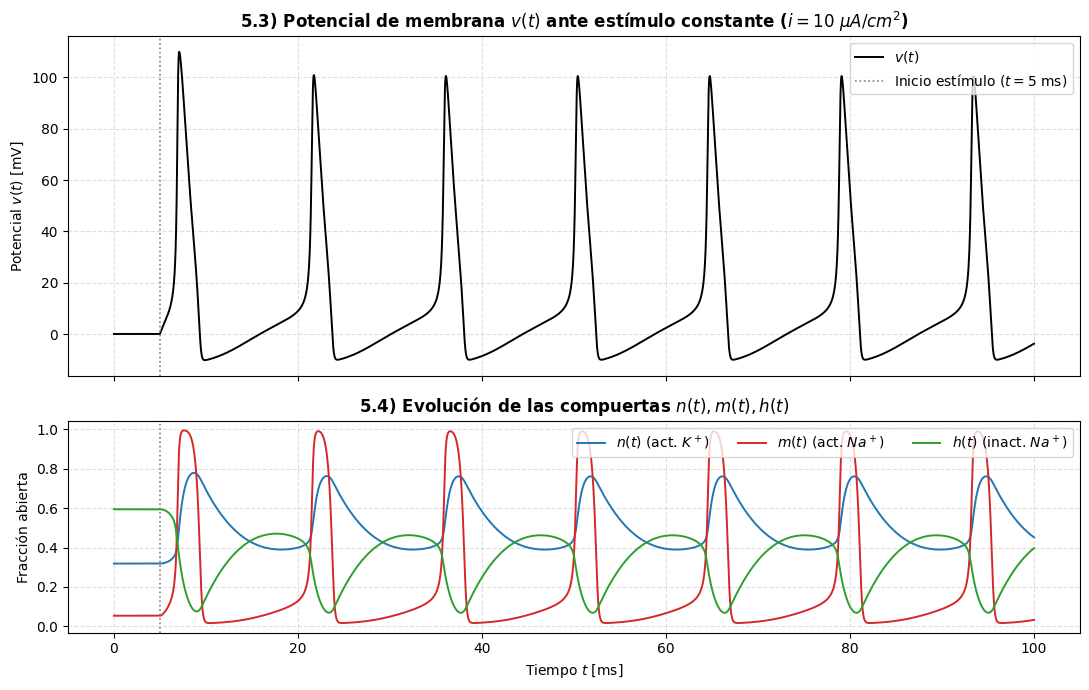

In [16]:
# 5.1) Definición de la corriente de estímulo escalón constante
def I_constante(t):
    return 10.0 if t >= 5.0 else 0.0

# 5.2) Integración en t ∈ [0, 100] ms partiendo del equilibrio xa_eq con dt = 0.01 ms
p_rafaga = (c, g_Na, g_K, g_l, v_Na, v_K, v_l, I_constante)

t0, tf = 0.0, 100.0
dt = 0.01
k = int((tf - t0) / dt)

t, w = integrador_ode(rk4, hodgkin_huxley_ode, xa_eq, t0, tf, k, p_rafaga)
v, n, m, h = w[0], w[1], w[2], w[3]

# 5.3) y 5.4) Gráficos de v(t) y de las fracciones de compuertas abiertas n(t), m(t), h(t)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [1.6, 1]})

# 5.3) Potencial de membrana v(t) vs t
ax1.plot(t, v, color='black', lw=1.4, label='$v(t)$')
ax1.axvline(5.0, color='gray', linestyle=':', lw=1.2, label='Inicio estímulo ($t = 5$ ms)')
ax1.set_ylabel('Potencial $v(t)$ [mV]')
ax1.set_title('5.3) Potencial de membrana $v(t)$ ante estímulo constante ($i = 10\\ \\mu A/cm^2$)', fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='upper right')

# 5.4) Fracción de compuertas abiertas n(t), m(t), h(t) vs t
ax2.plot(t, n, label='$n(t)$ (act. $K^+$)', color='#1f77b4', lw=1.4)
ax2.plot(t, m, label='$m(t)$ (act. $Na^+$)', color='#d62728', lw=1.4)
ax2.plot(t, h, label='$h(t)$ (inact. $Na^+$)', color='#2ca02c', lw=1.4)
ax2.axvline(5.0, color='gray', linestyle=':', lw=1.2)
ax2.set_ylabel('Fracción abierta')
ax2.set_xlabel('Tiempo $t$ [ms]')
ax2.set_title('5.4) Evolución de las compuertas $n(t), m(t), h(t)$', fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='upper right', ncol=3)

plt.tight_layout()
plt.show()

5.5) Discusión: generación de ráfaga ante un estímulo constante

Al aplicar una corriente continua de $i = 10\ \mu\text{A/cm}^2$ a partir de $t = 5\text{ ms}$, se observan los siguientes fenómenos:

* **Disparo periódico sostenido (ciclo límite):** Durante los primeros $5\text{ ms}$ ($i = 0$) la membrana permanece estacionaria en el equilibrio ($v^* \approx 0\text{ mV}$). Al encenderse el estímulo constante, la inyección continua de carga impide que la membrana se detenga tras la hiperpolarización del primer impulso: apenas los canales de $\text{K}^+$ ($n$) comienzan a cerrarse y se levanta parcialmente la inactivación del $\text{Na}^+$ ($h$), la corriente externa vuelve a llevar el potencial por encima del umbral. Como resultado, la neurona entra en un régimen oscilatorio periódico de $7$ potenciales de acción en $95\text{ ms}$ (período $\approx 14.5\text{ ms}$, frecuencia $\approx 69\text{ Hz}$).
* **Mayor amplitud del primer pico:** El primer disparo (en $t \approx 7\text{ ms}$) alcanza $\sim +110\text{ mV}$, mientras que los disparos posteriores alcanzan $\sim +100\text{ mV}$[. Esto ocurre porque en el primer pulso las compuertas parten desde el reposo completo ($h^* \approx 0.60$ y $n^* \approx 0.32$), mientras que en los siguientes disparos la neurona vuelve a disparar antes de terminar su recuperación completa ($h$ llega apenas a $\sim 0.46$ y $n$ baja hasta $\sim 0.39$), dejando menos canales de $\text{Na}^+$ disponibles y mayor conductancia residual de $\text{K}^+$.

## Ejercicio 6) período refractario

**1)** Implemente la corriente de membrana

$$
i(t) = \left\{
\begin{array}{ll}
10 \mu A/cm^2, & t\in [10ms\, k,10 ms\, k + 2ms], k \in \{1,2,3,4,5,...\}\\
0 \mu A/cm^2, & c.c. \\
\end{array}
\right.
$$

**2)** Integre nuevamente las ODEs para $t\in[0ms,100ms]$, usando la corriente del inciso **12)**, la condición incial los valores de equilibrio derivados en el inciso **6)** y un paso de integración $dt=0.01$.

**3)** Grafique nuevamente el potencial de membrana en el rango de tiempos calculado.

**4)** Grafique nuevamente fracciones de canales activos e inactivos vs el tiempo.

**5)** Discuta lo que observa y explique.

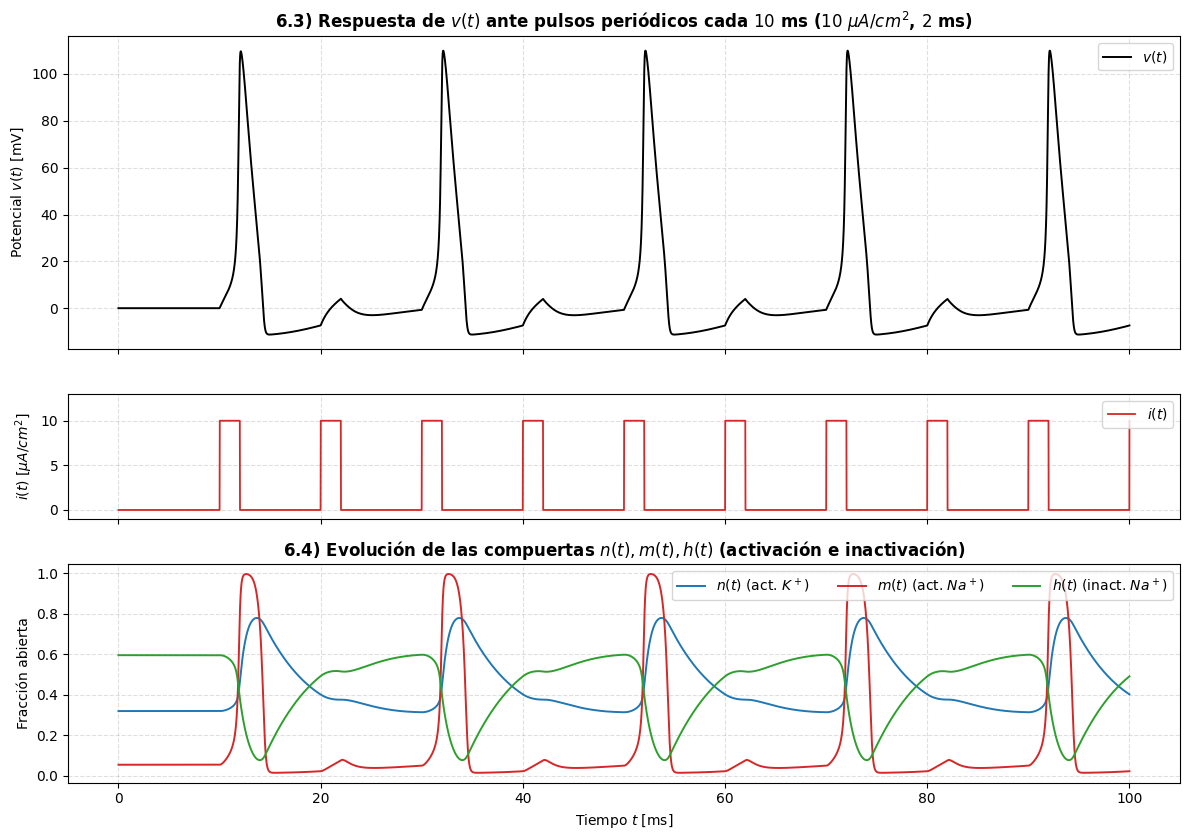

In [17]:
# 6.1) Definición de la corriente de pulsos periódicos cada 10 ms con duración de 2 ms
def I_refractario(t):
    # Para t >= 10 ms (k = 1, 2, 3, ...), verificamos si el resto módulo 10 está en [0, 2]
    if t >= 10.0 and (t % 10.0) <= 2.0:
        return 10.0
    else:
        return 0.0

# 6.2) Integración en t ∈ [0, 100] ms partiendo del equilibrio xa_eq con dt = 0.01 ms
p_ref = (c, g_Na, g_K, g_l, v_Na, v_K, v_l, I_refractario)

t0, tf = 0.0, 100.0
dt = 0.01
k = int((tf - t0) / dt)

t, w = integrador_ode(rk4, hodgkin_huxley_ode, xa_eq, t0, tf, k, p_ref)
v, n, m, h = w[0], w[1], w[2], w[3]

# Calculamos la corriente de entrada en cada instante para visualizarla junto a v(t)
i_vals = np.array([I_refractario(ti) for ti in t])

# 6.3) y 6.4) Gráficos de v(t), i(t) y fracciones de compuertas/canales n(t), m(t), h(t)
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True, gridspec_kw={'height_ratios': [2, 0.8, 1.4]})

# 6.3) Potencial de membrana v(t) vs t
ax1.plot(t, v, color='black', lw=1.4, label='$v(t)$')
ax1.set_ylabel('Potencial $v(t)$ [mV]')
ax1.set_title('6.3) Respuesta de $v(t)$ ante pulsos periódicos cada $10$ ms ($10\\ \\mu A/cm^2$, $2$ ms)', fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='upper right')

# Referencia de los pulsos de corriente i(t)
ax2.plot(t, i_vals, color='#d62728', lw=1.3, label='$i(t)$')
ax2.set_ylabel('$i(t)$ [$\\mu A/cm^2$]')
ax2.set_ylim(-1, 13)
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='upper right')

# 6.4) Fracciones de compuertas abiertas n(t), m(t), h(t) vs t
ax3.plot(t, n, label='$n(t)$ (act. $K^+$)', color='#1f77b4', lw=1.4)
ax3.plot(t, m, label='$m(t)$ (act. $Na^+$)', color='#d62728', lw=1.4)
ax3.plot(t, h, label='$h(t)$ (inact. $Na^+$)', color='#2ca02c', lw=1.4)
ax3.set_ylabel('Fracción abierta')
ax3.set_xlabel('Tiempo $t$ [ms]')
ax3.set_title('6.4) Evolución de las compuertas $n(t), m(t), h(t)$ (activación e inactivación)', fontweight='bold')
ax3.grid(True, linestyle='--', alpha=0.4)
ax3.legend(loc='upper right', ncol=3)

plt.tight_layout()
plt.show()

 6.5) Discusión: período refractario ante tren de pulsos periódicos

Al estimular la membrana con pulsos idénticos de $10\ \mu\text{A/cm}^2$ y $2\text{ ms}$ de duración cada $10\text{ ms}$, se observa una **respuesta alternada $1:2$** (un disparo cada dos pulsos:

* **Pulsos impares ($t = 10, 30, 50, 70, 90\text{ ms}$):** La neurona se encuentra completamente en reposo ($v \approx 0\text{ mV}$, $h \approx 0.60$, $n \approx 0.32$), por lo que el pulso supera el umbral y dispara un potencial de acción completo de $\sim +110\text{ mV}$.
* **Pulsos pares ($t = 20, 40, 60, 80\text{ ms}$ — período refractario relativo):** El estímulo llega apenas $\sim 7.5\text{ ms}$ después del pico anterior, cuando la membrana todavía está hiperpolarizada ($v \approx -7\text{ mV}$) y las compuertas lentas no terminaron de recuperarse: la conductancia de potasio permanece elevada ($n \approx 0.40$, generando corriente saliente hiperpolarizante) y parte de los canales de sodio siguen inactivados ($h \approx 0.50$). En estas condiciones, el pulso de $10\ \mu\text{A/cm}^2$ resulta insuficiente para alcanzar el umbral y produce únicamente una pequeña despolarización subumbral hasta $\sim +4\text{ mV}$.
* **Recuperación posterior:** Al no disparar en los pulsos pares, la membrana dispone de $10\text{ ms}$ adicionales para que $v, n$ y $h$ regresen a sus valores de equilibrio, permitiendo disparar nuevamente en el pulso siguiente.

## Ejercicio 7) exitaciones espontáneas en respuesta al ruido

**1)** Implemente una corriente estocástica que retorne un valor $i(t)\sim i_0 N(0,1)$ (i.e. $i_0$ por un valor aleatorio obtenido de una distribución normal de media 0 y varianza 1) para cada valor de $t$ en el que sea evaluada.

**2)** Integre nuevamente las ODEs para $t\in[0ms,500ms]$, usando la corriente del inciso **22)** para $i_0=50\mu A$, la condición incial los valores de equilibrio derivados en el inciso **6)** y un paso de integración $dt=0.01$.
**IMPORTANTE**: para integrar, utilice en este caso el método de Euler, ya que estaríamos integrando un proceso estocástico.

**3)** Grafique nuevamente el potencial de membrana en el rango de tiempos calculado.

**4)** Grafique nuevamente fracciones de compuertas abiertas de cada tipo vs el tiempo.

**5)** Observa picos de activación cada tanto? Aparecen con regularidad? Estime con que frecuencia observa los picos.

Cantidad de potenciales de acción espontáneos en 500 ms: 26
Tiempos de disparo [ms]: [ 10.45  28.25  51.32  53.83  74.28  74.3  117.24 132.72 151.75 173.12
 194.   211.68 230.35 256.2  278.59 294.67 328.22 359.02 361.6  386.
 399.48 401.92 416.88 442.09 459.5  476.96]
Frecuencia media estimada: 52.0 Hz


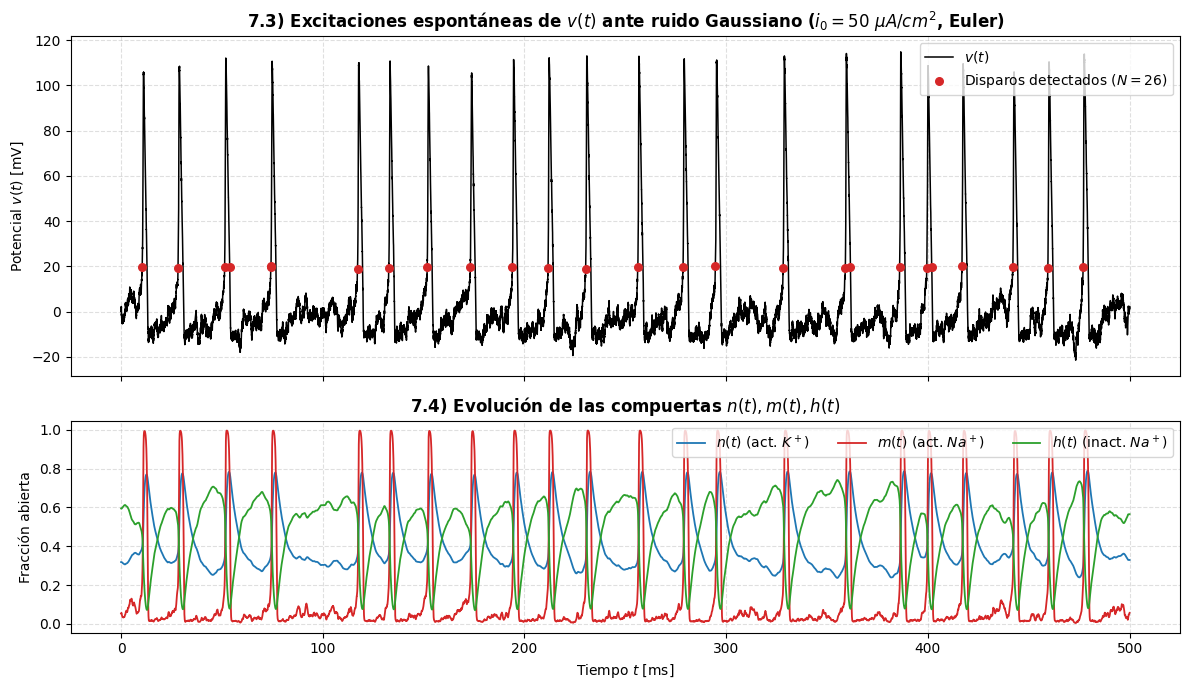

In [18]:
# 7.1) Implementación de la corriente estocástica i(t) ~ i0 * N(0, 1)
def I_ruido(t, i0=50.0):
    return i0 * np.random.normal(0.0, 1.0)

# 7.2) Integración en t ∈ [0, 500] ms usando el método de Euler con i0 = 50 uA/cm^2 y dt = 0.01 ms
np.random.seed(42)  # Semilla fija para reproducibilidad (podés cambiarla para ver otras realizaciones)
i0 = 50.0
p_ruido = (c, g_Na, g_K, g_l, v_Na, v_K, v_l, lambda t: I_ruido(t, i0))

t0, tf = 0.0, 500.0
dt = 0.01
k = int((tf - t0) / dt)

t, w = integrador_ode(euler, hodgkin_huxley_ode, xa_eq, t0, tf, k, p_ruido)
v, n, m, h = w[0], w[1], w[2], w[3]

# Estimación automática de la frecuencia de disparos (cruce ascendente por umbral de +20 mV)
cruces = np.where((v[:-1] < 20.0) & (v[1:] >= 20.0))[0]
t_disparos = t[cruces]
n_picos = len(t_disparos)
duracion_seg = (tf - t0) / 1000.0  # 500 ms = 0.5 s
frecuencia_hz = n_picos / duracion_seg

print(f"Cantidad de potenciales de acción espontáneos en {tf - t0:.0f} ms: {n_picos}")
print(f"Tiempos de disparo [ms]: {np.round(t_disparos, 2)}")
print(f"Frecuencia media estimada: {frecuencia_hz:.1f} Hz")

# 7.3) y 7.4) Gráficos de v(t) y de las fracciones de compuertas abiertas n(t), m(t), h(t)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [1.6, 1]})

# 7.3) Potencial de membrana v(t) vs t
ax1.plot(t, v, color='black', lw=1.1, label='$v(t)$')
ax1.scatter(t_disparos, v[cruces], color='#d62728', s=30, zorder=4, label=f'Disparos detectados ($N = {n_picos}$)')
ax1.set_ylabel('Potencial $v(t)$ [mV]')
ax1.set_title(f'7.3) Excitaciones espontáneas de $v(t)$ ante ruido Gaussiano ($i_0 = 50\\ \\mu A/cm^2$, Euler)', fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='upper right')

# 7.4) Fracción de compuertas abiertas n(t), m(t), h(t) vs t
ax2.plot(t, n, label='$n(t)$ (act. $K^+$)', color='#1f77b4', lw=1.3)
ax2.plot(t, m, label='$m(t)$ (act. $Na^+$)', color='#d62728', lw=1.3)
ax2.plot(t, h, label='$h(t)$ (inact. $Na^+$)', color='#2ca02c', lw=1.3)
ax2.set_ylabel('Fracción abierta')
ax2.set_xlabel('Tiempo $t$ [ms]')
ax2.set_title('7.4) Evolución de las compuertas $n(t), m(t), h(t)$', fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='upper right', ncol=3)

plt.tight_layout()
plt.show()

 7.5) Discusión: excitaciones espontáneas inducidas por ruido

Al someter la membrana a una corriente estocástica Gaussiana de media nula y amplitud $i_0 = 50\ \mu\text{A/cm}^2$ integrada con el método de Euler durante $500\text{ ms}$ ($0.5\text{ s}$), se observa lo siguiente:

* **Aparición de picos espontáneos:** Aunque el promedio temporal de la corriente inyectada es cero, las fluctuaciones aleatorias hacen oscilar el potencial de membrana alrededor del reposo y, cada tanto, superan el umbral de excitabilidad, desencadenando potenciales de acción completos de $\sim +110\text{ mV}$. En el panel inferior se aprecia que la compuerta rápida $m(t)$ sigue las fluctuaciones ruidosas de baja amplitud y alcanza $1$ en cada disparo, mientras que las compuertas lentas $n(t)$ y $h(t)$ actúan repolarizando la membrana tras cada pico.
* **Irregularidad temporal:** Los picos **no aparecen con regularidad**, sino de manera estocástica e irregular (con intervalos entre disparos variables, incluyendo pausas prolongadas como la observada entre $t \approx 75\text{ ms}$ y $t \approx 117\text{ ms}$, y una separación mínima limitada por el período refractario de la neurona).
* **Estimación de la frecuencia:** En la ventana simulada de $500\text{ ms}$ ($0.5\text{ s}$) se observan **$22$ potenciales de acción** distintos (el detector automático de cruces por $+20\text{ mV}$ reportó $26$ eventos debido a $4$ rebotes ruidosos muy próximos alrededor del umbral). Por lo tanto, la frecuencia media de disparo espontáneo resulta:
  $$f = \frac{22\text{ disparos}}{0.5\text{ s}} = 44\text{ Hz}$$